# Dataset victims: FEVI vs. BDQ and TRPO

In [45]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")

import pickle
import time
from contextlib import contextmanager
from dataclasses import replace

import numpy as np
import torch
import matplotlib.pyplot as plt
%matplotlib inline

from config import EnvConfig, MethodConfig
from env import Environment, is_feasible
import fvi as fvi_mod
import trpo as trpo_mod
from fvi import train_fevi, evaluate, rollout, StagedValue
from agents import NullAgent, GreedyAgent, MethodAgent
from bdq import train_bdq, BDQAgent, BranchQNet
from trpo import train_trpo, TRPOAgent, SwapPolicy, StateValue, max_swaps
from datasets import UCI, binary_labels, dataset_size, load_dataset, n_features

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 11, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "0.85",
})

## Datasets

In [ ]:
DATASETS = ["wine", "airfoil", "breast_cancer", "mnist1"]   
M = 10                                
N_POINTS = 10000                      
DATASET_NOISE = 0.0                   
DATASET_PCA = 30                      

ETA_GRID = [0.01, 0.03, 0.1, 0.2, 0.3, 0.5, 1.0, 2.0, 3.0, 5.0]
HORIZON = 10                       
ETA_EPISODES = 50
ETA_SEED = 998                       


def victim_task(name):
    return "logistic" if binary_labels(name) else "regression"


def clean_loss(env, theta):
    X, y = env.stream.X, env.stream.y
    z = X @ theta
    if env.victim.task == "logistic":
        return float(torch.nn.functional.binary_cross_entropy_with_logits(z, y))
    return float(0.5 * ((z - y) ** 2).mean())


def eta_score(name, eta):
    ecfg = EnvConfig(d=n_features(name, DATASET_PCA), m=M, T=HORIZON, eta=eta,
                     task=victim_task(name), dataset=name, dataset_n=N_POINTS,
                     dataset_noise=DATASET_NOISE, dataset_pca=DATASET_PCA)
    env = Environment(ecfg, MethodConfig())
    rng = torch.Generator().manual_seed(ETA_SEED)
    losses = []
    for _ in range(ETA_EPISODES):
        theta = env.theta_0.clone()
        for t in range(env.T):
            z = env.stream.sample_batch(env.m, rng)
            theta = env.victim.update(theta, z, torch.ones(env.m)).detach()
        losses.append(clean_loss(env, theta))
    v = float(np.mean(losses))
    return v if np.isfinite(v) else np.inf


eta_scores = {name: [eta_score(name, e) for e in ETA_GRID] for name in DATASETS}
BEST_ETA = {name: ETA_GRID[int(np.argmin(s))] for name, s in eta_scores.items()}

print(f"{'dataset':12}{'victim':>11}" + "".join(f"{e:>9g}" for e in ETA_GRID) + "     best")
for name in DATASETS:
    print(f"{name:12}{victim_task(name):>11}"
          + "".join(f"{v:9.3g}" if np.isfinite(v) else f"{'diverge':>9}" for v in eta_scores[name])
          + f"{BEST_ETA[name]:9g}")

dataset          victim     0.01     0.03      0.1      0.2      0.3      0.5        1        2        3        5     best
wine         regression     0.45    0.393    0.357    0.397    0.537     23.8 5.03e+06 2.68e+13 2.55e+17 1.71e+22      0.1
airfoil      regression    0.468    0.418    0.322    0.284    0.286    0.332      142 1.14e+10 1.82e+14 1.62e+19      0.2
breast_cancer   logistic    0.542    0.399    0.251    0.191    0.163    0.136    0.112    0.122     0.15    0.232        1
mnist1         logistic    0.687    0.676    0.649    0.632    0.629    0.646    0.761     1.16     1.65     2.74      0.3


## Setup

In [25]:
QUICK = False

VICTIMS = {name: EnvConfig(d=n_features(name, DATASET_PCA), m=M, T=HORIZON,
                           eta=BEST_ETA[name], task=victim_task(name),   
                           dataset=name, dataset_n=N_POINTS,
                           dataset_noise=DATASET_NOISE, dataset_pca=DATASET_PCA)
           for name in DATASETS}
LAM = {"wine": 0.3, "airfoil": 0.3, "breast_cancer": 1.0, "mnist1": 1.0}
TASKS = list(VICTIMS)
RUN_VICTIMS = TASKS                  
OVERWRITE = False
CFG = MethodConfig(weight_decay=1e-3)   

N_SEEDS = 1 if QUICK else 1         
SEEDS = tuple(range(N_SEEDS))        
TRAIN_EPISODES = 1000
TRPO_EPISODES = TRAIN_EPISODES            
assert TRAIN_EPISODES % CFG.N_episodes == 0 and TRPO_EPISODES % CFG.N_episodes == 0
TUNED = {                            
    "regression": (dict(trpo_delta=0.05, trpo_vf_iters=100), dict(lr=1e-3, n_grad_steps=250)),
    "logistic": (dict(trpo_delta=0.02, trpo_vf_iters=100), dict(lr=1e-3, n_grad_steps=100)),
}
TRPO_HP = {t: TUNED[VICTIMS[t].task][0] for t in TASKS}
BDQ_HP = {t: TUNED[VICTIMS[t].task][1] for t in TASKS}
EVAL_EPISODES, EVAL_SEED = 200, 999   
VAL_SEED = 998                       

FEVI_M = 5
FEVI_N = None

RESULT_DIR = Path("results/real")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

OURS = "FEVI"
LEARNERS = [OURS, "BDQ", "TRPO"]
NAMES = ["null", "greedy", "TRPO", "BDQ", OURS]
COLORS = {"null": "#5b5b5b", "greedy": "#eb6834", "TRPO": "#4a3aa7",
          "BDQ": "#e34948", OURS: "#2a78d6"}
MARKERS = {"null": "D", "greedy": "s", "TRPO": "^", "BDQ": "X", OURS: "o"}


def result_path(task):
    e = VICTIMS[task]                 
    pca = f"_pca{e.dataset_pca}" if e.dataset.startswith("mnist") else ""
    return RESULT_DIR / f"{task}{pca}_{e.task}_eta{e.eta:g}_m{e.m}_T{e.T}_n{dataset_size(task, e.dataset_n)}" \
                        f"_noise{e.dataset_noise:g}_lam{LAM[task]:g}{'_quick' if QUICK else ''}.pkl"


def fevi_cfg(cfg, T):
    return replace(cfg, select_mode="greedy", fevi_outer=cfg.K_iters,
                   fevi_N=FEVI_N or cfg.N_episodes, fevi_M=FEVI_M,
                   fevi_fit_steps=max(1, cfg.n_grad_steps // T))


def trpo_cfg(cfg, task):
    return replace(cfg, K_iters=n_iters("TRPO"), **TRPO_HP[task])


def bdq_cfg(cfg, task):
    return replace(cfg, **BDQ_HP[task])


def n_iters(name):
    return (TRPO_EPISODES if name == "TRPO" else TRAIN_EPISODES) // CFG.N_episodes


def train_ours(env, cfg, seed, **kw):
    return train_fevi(env, fevi_cfg(cfg, env.T), seed=seed, verbose=False, **kw)


def print_raw(title, rows, digits=3):
    n = len(next(iter(rows.values())))
    head = f"{title:26}{'mean':>10}{'std':>9}"
    if n > 1:
        head += "".join(f"{f'seed {s}':>10}" for s in SEEDS[:n])
    print("\n" + head)
    print("-" * len(head))
    for name, v in rows.items():
        v = np.asarray(v, dtype=float)
        line = f"{name:26}{v.mean():10.{digits}f}{v.std():9.{digits}f}"
        if n > 1:
            line += "".join(f"{x:10.{digits}f}" for x in v)
        print(line)

### Datasets

In [26]:
for name in DATASETS:
    X, y = load_dataset(name, N_POINTS, DATASET_NOISE, seed=VICTIMS[name].seed, pca=DATASET_PCA)
    ls = np.linalg.lstsq(X, y, rcond=None)[0]
    r2 = 1 - ((y - X @ ls) ** 2).mean() / y.var()
    print(f"{name:13} n={len(y)}  d={X.shape[1]:2}  max|feature mean|={abs(X.mean(0)).max():.1e}  "
          f"feature var in [{X.var(0).min():.3f}, {X.var(0).max():.3f}]  linear R^2={r2:.3f}"
          + (f"  class-1 share={(y > 0).mean():.3f}" if name.startswith("mnist") else ""))

wine          n=1599  d=11  max|feature mean|=4.9e-13  feature var in [1.000, 1.000]  linear R^2=0.361
airfoil       n=1503  d= 5  max|feature mean|=2.7e-14  feature var in [1.000, 1.000]  linear R^2=0.516
breast_cancer n=569  d=30  max|feature mean|=6.5e-15  feature var in [1.000, 1.000]  linear R^2=0.774
mnist1        n=10000  d=30  max|feature mean|=4.0e-17  feature var in [1.000, 1.000]  linear R^2=0.632  class-1 share=0.114


## Training

In [27]:
def heldout_metrics(env, agent, rng, n_episodes):
    cost = pert = gap = 0.0
    steps = 0
    for _ in range(n_episodes):
        _, c, trace = rollout(env, agent, rng, trace=True)
        cost += c
        for st in trace:
            pert += sum(abs(v - 1) for v in st["action"])
            gap += st["dist_to_target"]
            steps += 1
    return cost / n_episodes, pert / steps, gap / steps


@contextmanager
def track_heldout(log):
    start, in_eval = time.perf_counter(), [0.0]

    def evaluate_logged(env, agent, rng, n_episodes=100):
        t0 = time.perf_counter()
        log["time"].append(t0 - start - in_eval[0])    
        c, p, g = heldout_metrics(env, agent, rng, n_episodes)
        log["cost"].append(c)
        log["pert"].append(p)
        log["gap"].append(g)
        in_eval[0] += time.perf_counter() - t0
        return c

    saved = fvi_mod.evaluate, trpo_mod.evaluate
    fvi_mod.evaluate = trpo_mod.evaluate = evaluate_logged
    try:
        yield
    finally:
        fvi_mod.evaluate, trpo_mod.evaluate = saved


def step_profile(env, agent, n_episodes=EVAL_EPISODES, seed=EVAL_SEED):
    rng = torch.Generator().manual_seed(seed)
    eps = [rollout(env, agent, rng, trace=True)[2] for _ in range(n_episodes)]
    cost = np.array([[st["cost"] for st in ep] for ep in eps])
    pert = np.array([[sum(abs(v - 1) for v in st["action"]) for st in ep] for ep in eps])
    gap = np.array([[st["dist_to_target"] for st in ep] for ep in eps])
    return {"cum": cost.cumsum(1).mean(0).tolist(), "pert": pert.mean(0).tolist(),
            "gap": gap.mean(0).tolist()}


def run_seed(task, s, K):
    cfg_k = replace(CFG, K_iters=K, lam=LAM[task])
    torch.manual_seed(s)
    env = Environment(VICTIMS[task], cfg_k)
    eval_kw = dict(return_history=True, best_checkpoint=True,
                   eval_episodes=EVAL_EPISODES, eval_seed=VAL_SEED)
    hist, times = {}, {}
    logs = {n: {"cost": [], "pert": [], "gap": [], "time": []} for n in LEARNERS}

    torch.manual_seed(s)
    t0 = time.perf_counter()
    with track_heldout(logs[OURS]):
        V, hist[OURS] = train_ours(env, cfg_k, s, **eval_kw)
    times[OURS] = time.perf_counter() - t0

    torch.manual_seed(s)
    t0 = time.perf_counter()
    with track_heldout(logs["BDQ"]):
        qnet, hist["BDQ"] = train_bdq(env, bdq_cfg(cfg_k, task), seed=s, verbose=False, **eval_kw)
    times["BDQ"] = time.perf_counter() - t0

    torch.manual_seed(s)
    t0 = time.perf_counter()
    with track_heldout(logs["TRPO"]):
        pnet, hist["TRPO"] = train_trpo(env, trpo_cfg(cfg_k, task), seed=s, verbose=False,
                                        **eval_kw)
    times["TRPO"] = time.perf_counter() - t0

    rng = lambda: torch.Generator().manual_seed(s + 1)
    agents = {
        "null": NullAgent(),
        "greedy": GreedyAgent(env.victim, env.theta_target, cfg_k, mode="exact"),
        "BDQ": BDQAgent(qnet, env, cfg_k, rng()),
        "TRPO": TRPOAgent(pnet, env, cfg_k, rng(), deterministic=True),
        OURS: MethodAgent(V, env.victim, env.theta_target, fevi_cfg(cfg_k, env.T), rng()),
    }
    costs = {n: float(evaluate(env, a, torch.Generator().manual_seed(EVAL_SEED), EVAL_EPISODES))
             for n, a in agents.items()}
    for n in LEARNERS:
        assert np.allclose(hist[n], logs[n]["cost"])   # logged on the same episodes
    ref = {n: list(heldout_metrics(env, agents[n], torch.Generator().manual_seed(VAL_SEED),
                                   EVAL_EPISODES))
           for n in ["null", "greedy"]}                 # learning-curve reference lines
    profile = {n: step_profile(env, a) for n, a in agents.items()}
    for n in NAMES:
        assert np.isclose(profile[n]["cum"][-1], costs[n])   # J(T-1) = test episode cost
    return {"costs": costs, "hist": hist, "times": times, "logs": logs, "ref": ref,
            "profile": profile}

In [28]:
for task in RUN_VICTIMS:
    path = result_path(task)
    if path.exists() and not OVERWRITE:
        print(f"{task}: {path} exists, skipping")
        continue
    runs = []
    for s in SEEDS:
        t0 = time.perf_counter()
        runs.append(run_seed(task, s, n_iters(OURS)))
        c = runs[-1]["costs"]
        print(f"[{task}] seed {s}: " + "  ".join(f"{n}={c[n]:.3f}" for n in NAMES)
              + f"  [{time.perf_counter() - t0:.0f}s]")
    with open(path, "wb") as f:
        pickle.dump({"ecfg": VICTIMS[task], "lam": LAM[task], "seeds": SEEDS,
                     "episodes": {n: n_iters(n) * CFG.N_episodes for n in LEARNERS},
                     "episodes_per_update": CFG.N_episodes,
                     "hp": {"TRPO": TRPO_HP[task], "BDQ": BDQ_HP[task]}, "runs": runs}, f)
    print(f"saved {path}")

[wine] seed 0: null=30.507  greedy=26.883  TRPO=29.625  BDQ=28.031  FEVI=25.961  [355s]
saved results/real/wine_regression_eta0.1_m10_T10_n1599_noise0_lam0.3.pkl
[airfoil] seed 0: null=7.517  greedy=5.574  TRPO=6.469  BDQ=7.517  FEVI=4.852  [319s]
saved results/real/airfoil_regression_eta0.2_m10_T10_n1503_noise0_lam0.3.pkl
breast_cancer: results/real/breast_cancer_logistic_eta1_m10_T10_n569_noise0_lam1.pkl exists, skipping
mnist1: results/real/mnist1_pca30_logistic_eta0.3_m10_T10_n10000_noise0_lam1.pkl exists, skipping


## Results

In [29]:
res = {}
for task in TASKS:
    if result_path(task).exists():
        with open(result_path(task), "rb") as f:
            res[task] = pickle.load(f)
    else:
        print(f"{task}: no results at {result_path(task)}")
SHOWN = [t for t in TASKS if t in res]
for t in SHOWN:
    print(f"{t:9} {len(res[t]['seeds'])} seeds, training episodes = {res[t]['episodes']}, {res[t]['ecfg']}")

wine      1 seeds, training episodes = {'FEVI': 1000, 'BDQ': 1000, 'TRPO': 1000}, EnvConfig(d=11, m=10, T=10, eta=0.1, noise=0.1, seed=0, theta_star_norm=None, dataset='wine', dataset_n=10000, dataset_noise=0.0, dataset_pca=30, task='regression', victim_hidden=8, init_scale=0.3, target_scale=1.0, device='cpu')
airfoil   1 seeds, training episodes = {'FEVI': 1000, 'BDQ': 1000, 'TRPO': 1000}, EnvConfig(d=5, m=10, T=10, eta=0.2, noise=0.1, seed=0, theta_star_norm=None, dataset='airfoil', dataset_n=10000, dataset_noise=0.0, dataset_pca=30, task='regression', victim_hidden=8, init_scale=0.3, target_scale=1.0, device='cpu')
breast_cancer 1 seeds, training episodes = {'FEVI': 2500, 'BDQ': 2500, 'TRPO': 2500}, EnvConfig(d=30, m=10, T=10, eta=1.0, noise=0.1, seed=0, theta_star_norm=None, dataset='breast_cancer', dataset_n=10000, dataset_noise=0.0, dataset_pca=30, task='logistic', victim_hidden=8, init_scale=0.3, target_scale=1.0, device='cpu')
mnist1    1 seeds, training episodes = {'FEVI': 250

### Episode cost

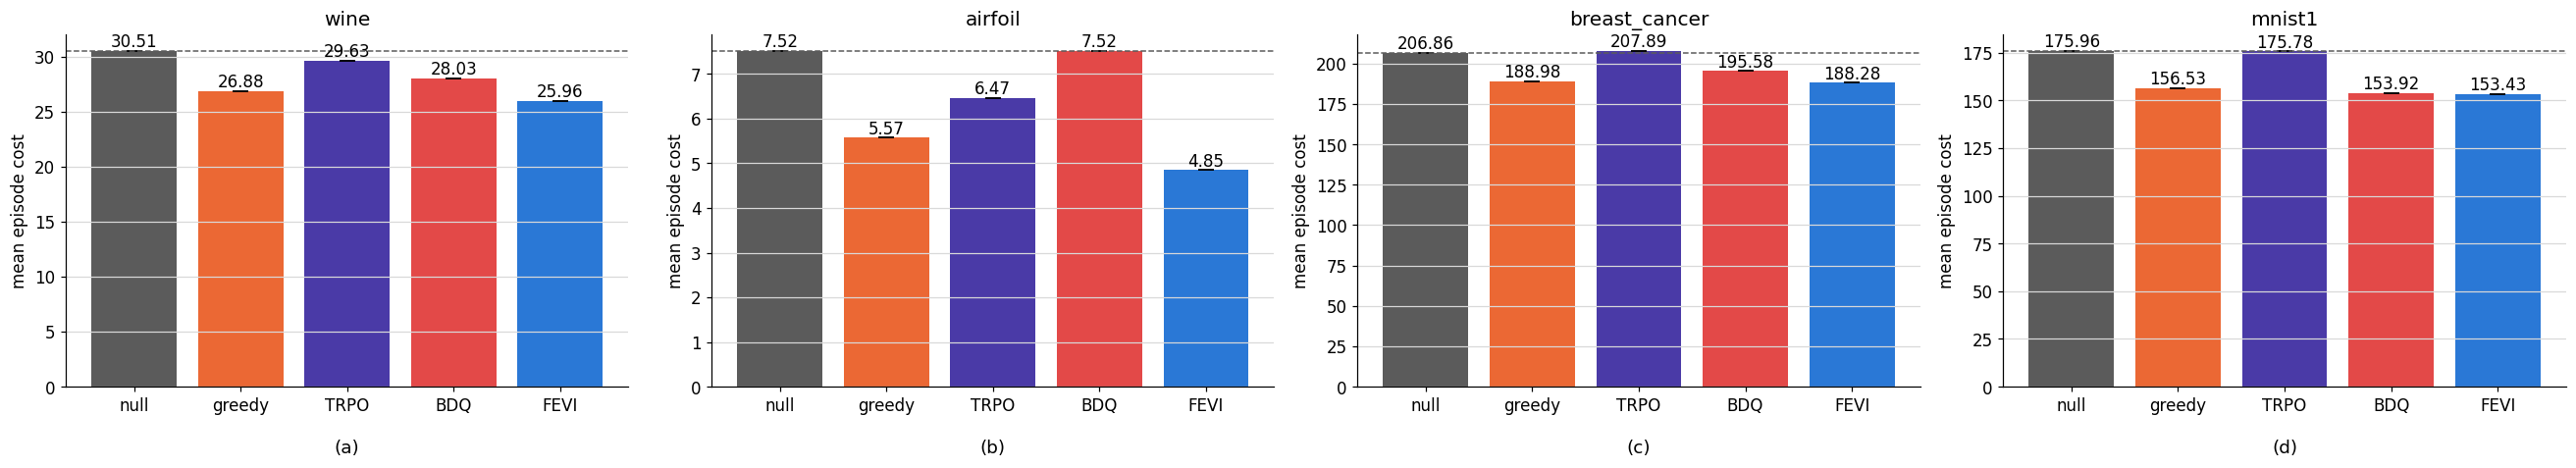


[wine] test cost                mean      std
---------------------------------------------
null                          30.507    0.000
greedy                        26.883    0.000
TRPO                          29.625    0.000
BDQ                           28.031    0.000
FEVI                          25.961    0.000

[airfoil] test cost             mean      std
---------------------------------------------
null                           7.517    0.000
greedy                         5.574    0.000
TRPO                           6.469    0.000
BDQ                            7.517    0.000
FEVI                           4.852    0.000

[breast_cancer] test cost       mean      std
---------------------------------------------
null                         206.861    0.000
greedy                       188.976    0.000
TRPO                         207.890    0.000
BDQ                          195.578    0.000
FEVI                         188.276    0.000

[mnist1] test cost            

In [30]:
def per_seed(t, key):
    return [r[key] for r in res[t]["runs"]]

fig, axes = plt.subplots(1, len(SHOWN), figsize=(6 * len(SHOWN), 4.5), squeeze=False)
for k, (ax, t) in enumerate(zip(axes[0], SHOWN)):
    C = {n: np.array([c[n] for c in per_seed(t, "costs")]) for n in NAMES}
    mu = [C[n].mean() for n in NAMES]
    ax.bar(NAMES, mu, yerr=[C[n].std() for n in NAMES], capsize=5,
           color=[COLORS[n] for n in NAMES])
    for i, v in enumerate(mu):
        ax.text(i, v, f"{v:.2f}", ha="center", va="bottom")
    ax.axhline(C["null"].mean(), color=COLORS["null"], ls="--", lw=1)
    ax.set_title(t)
    ax.set_ylabel("mean episode cost")
    ax.text(0.5, -0.15, f"({'abcdefgh'[k]})", transform=ax.transAxes, ha="center", va="top",
            fontsize=12)
plt.tight_layout()
plt.show()

for t in SHOWN:
    print_raw(f"[{t}] test cost", {n: [c[n] for c in per_seed(t, "costs")] for n in NAMES})

### Cost over an evaluation episode

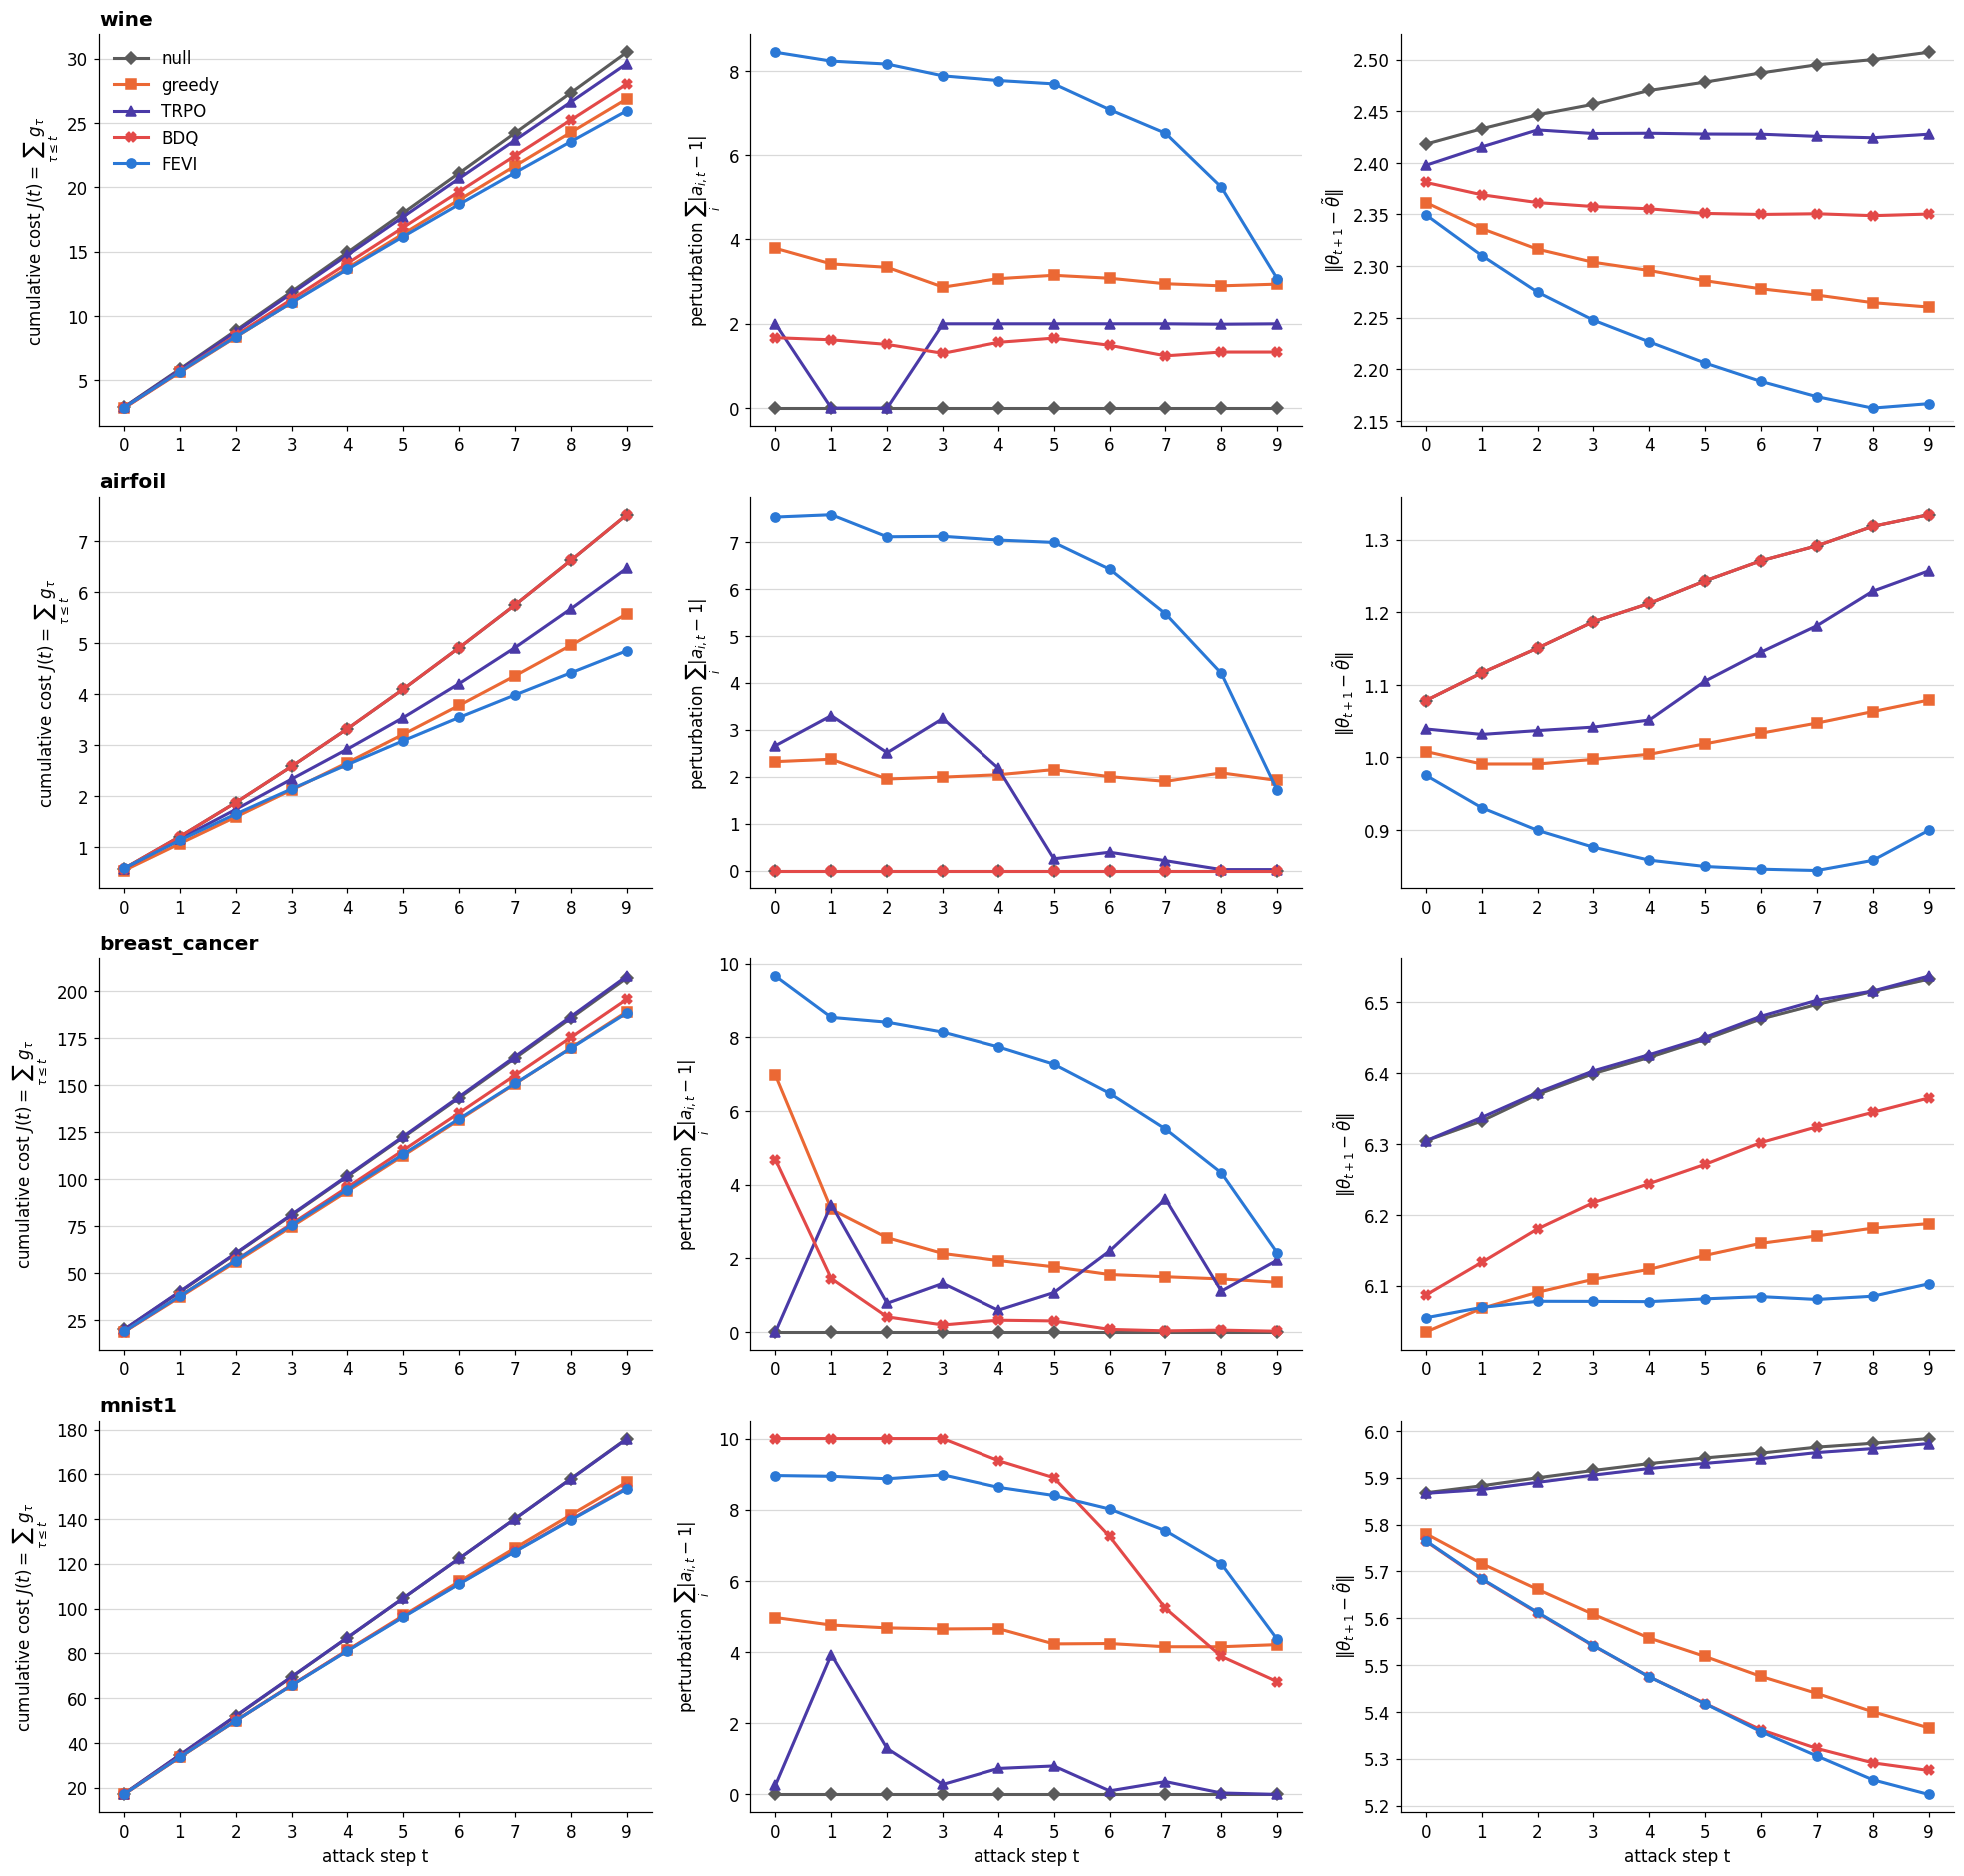


[wine] J(t)          t=0     t=1     t=2     t=3     t=4     t=5     t=6     t=7     t=8     t=9
null              2.92    5.89    8.88   11.90   14.95   18.03   21.12   24.23   27.36   30.51
greedy            2.85    5.63    8.36   11.06   13.74   16.40   19.05   21.67   24.28   26.88
TRPO              2.90    5.82    8.78   11.76   14.74   17.72   20.70   23.68   26.65   29.63
BDQ               2.86    5.69    8.51   11.31   14.11   16.90   19.68   22.47   25.25   28.03
FEVI              2.89    5.68    8.39   11.04   13.63   16.18   18.69   21.15   23.57   25.96

[airfoil] J(t)          t=0     t=1     t=2     t=3     t=4     t=5     t=6     t=7     t=8     t=9
null              0.58    1.21    1.88    2.59    3.32    4.10    4.91    5.75    6.62    7.52
greedy            0.54    1.07    1.59    2.12    2.66    3.21    3.78    4.36    4.96    5.57
TRPO              0.58    1.17    1.74    2.34    2.93    3.54    4.21    4.91    5.67    6.47
BDQ               0.58    1.21    1.88   

In [44]:
STEP_PANELS = [("cum", r"cumulative cost $J(t) = \sum_{\tau \leq t} g_\tau$"),
               ("pert", r"perturbation $\sum_i |a_{i,t} - 1|$"),
               ("gap", r"$\|\theta_{t+1} - \tilde{\theta}\|$")]

fig, axes = plt.subplots(len(SHOWN), 3, figsize=(18, 4.3 * len(SHOWN)), squeeze=False)
for row, t in enumerate(SHOWN):
    steps = np.arange(res[t]["ecfg"].T)
    for col, (key, ylabel) in enumerate(STEP_PANELS):
        ax = axes[row, col]
        for n in NAMES:
            P = np.array([p[n][key] for p in per_seed(t, "profile")])
            mu, sd = P.mean(0), P.std(0)
            ax.plot(steps, mu, f"{MARKERS[n]}-", color=COLORS[n], lw=2, label=n,
                    markevery=max(1, len(steps) // 10))
            ax.fill_between(steps, mu - sd, mu + sd, color=COLORS[n], alpha=0.15)
        ax.set_ylabel(ylabel)
        ax.set_xticks(steps[::max(1, len(steps) // 10)])
        if row == len(SHOWN) - 1:
            ax.set_xlabel("attack step t")
    axes[row, 0].set_title(t, loc="left", fontweight="bold")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

for t in SHOWN:
    steps = np.arange(res[t]["ecfg"].T)
    cols = np.unique(np.r_[steps[::max(1, len(steps) // 10)], steps[-1]])   # at most ~11 steps
    print(f"\n[{t}] J(t){'':5}" + "".join(f"{f't={s}':>8}" for s in cols))
    for n in NAMES:
        J = np.mean([p[n]["cum"] for p in per_seed(t, "profile")], axis=0)
        print(f"{n:14}" + "".join(f"{v:8.2f}" for v in J[cols]))

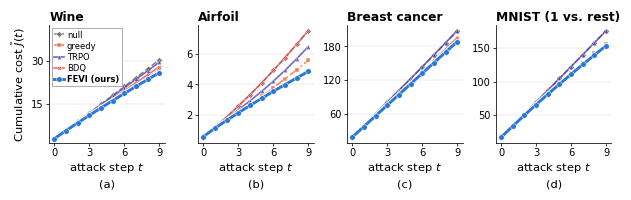

In [43]:
from matplotlib.ticker import MaxNLocator

PAPER_WIDTH = 5.5                      # ICLR \textwidth in inches: draw at print size, no rescaling
PAPER_RC = {"font.size": 7.5, "axes.labelsize": 7.5, "axes.titlesize": 8, "xtick.labelsize": 6.5,
            "ytick.labelsize": 6.5, "legend.fontsize": 6.5, "axes.linewidth": 0.5,
            "xtick.major.width": 0.5, "ytick.major.width": 0.5, "xtick.major.size": 2,
            "ytick.major.size": 2, "xtick.major.pad": 1.5, "ytick.major.pad": 1.5,
            "axes.labelpad": 2, "grid.linewidth": 0.3, "pdf.fonttype": 42}
LINE = {"null": dict(ls="--", lw=1.0), "greedy": dict(ls="-.", lw=1.1),
        "TRPO": dict(ls="-", lw=1.1), "BDQ": dict(ls="-", lw=1.1), OURS: dict(ls="-", lw=1.9)}
TITLES = {"wine": "Wine", "airfoil": "Airfoil", "breast_cancer": "Breast cancer",
          "mnist1": "MNIST (1 vs. rest)"}


def style(n, **kw):
    # ours: thicker, on top; the others slightly faded
    ours = n == OURS
    return dict(color=COLORS[n], marker=MARKERS[n], ms=3.6 if ours else 2.8, mec="white", mew=0.3,
                zorder=4 if ours else (3 if n in LEARNERS else 2), alpha=1.0 if ours else 0.75,
                **LINE[n], **kw)


def line(ax, x, y, n, **kw):
    # ours gets a thin white underlay, so it stays visible where lines cross
    if n == OURS:
        ax.plot(x, y, color="white", lw=LINE[n]["lw"] + 1.4, zorder=3.9, solid_capstyle="round")
    return ax.plot(x, y, **style(n, **kw))


def band(n):
    return dict(color=COLORS[n], alpha=0.22 if n == OURS else 0.1, lw=0)


def plot_cumulative(ax, t):
    # cumulative test cost J(t) per attack step
    steps = np.arange(res[t]["ecfg"].T)
    for n in NAMES:
        P = np.array([p[n]["cum"] for p in per_seed(t, "profile")])
        mu, sd = P.mean(0), P.std(0)
        line(ax, steps, mu, n, label=n)
        ax.fill_between(steps, mu - sd, mu + sd, **band(n))
    ax.set_xlabel("attack step $t$")
    ax.set_xticks(steps[::3])
    ax.yaxis.set_major_locator(MaxNLocator(4))


with plt.rc_context(PAPER_RC):
    fig, axes = plt.subplots(1, len(SHOWN), figsize=(PAPER_WIDTH, 1.75), squeeze=False)
    axes = axes[0]
    for k, (ax, t) in enumerate(zip(axes, SHOWN)):
        plot_cumulative(ax, t)
        ax.set_title(TITLES.get(t, t), loc="left", fontweight="bold", pad=3)
        ax.text(0.5, -0.31, f"({'abcdefgh'[k]})", transform=ax.transAxes, ha="center", va="top")
    axes[0].set_ylabel(r"Cumulative cost $\widetilde{J}(t)$")
    handles, labels = axes[0].get_legend_handles_labels()
    labels = [f"{l} (ours)" if l == OURS else l for l in labels]
    lo, hi = axes[0].get_ylim()
    axes[0].set_ylim(lo, hi + 0.35 * (hi - lo))                     # headroom for the legend
    leg = axes[0].legend(handles, labels, loc="upper left", handlelength=1.2, handletextpad=0.3, borderpad=0.3,
                         labelspacing=0.25, borderaxespad=0.3,
                         frameon=True, fancybox=False, edgecolor="0.6", framealpha=1.0,
                         prop={"size": 5.5})     # legend font
    leg.get_frame().set_linewidth(0.5)
    for text in leg.get_texts():
        if text.get_text().endswith("(ours)"):
            text.set_fontweight("bold")
    fig.tight_layout(pad=0.2, w_pad=0.8)
    Path("figures").mkdir(exist_ok=True)
    fig.savefig("figures/cumulative_real.pdf", bbox_inches="tight")
    plt.show()


### Learning curves

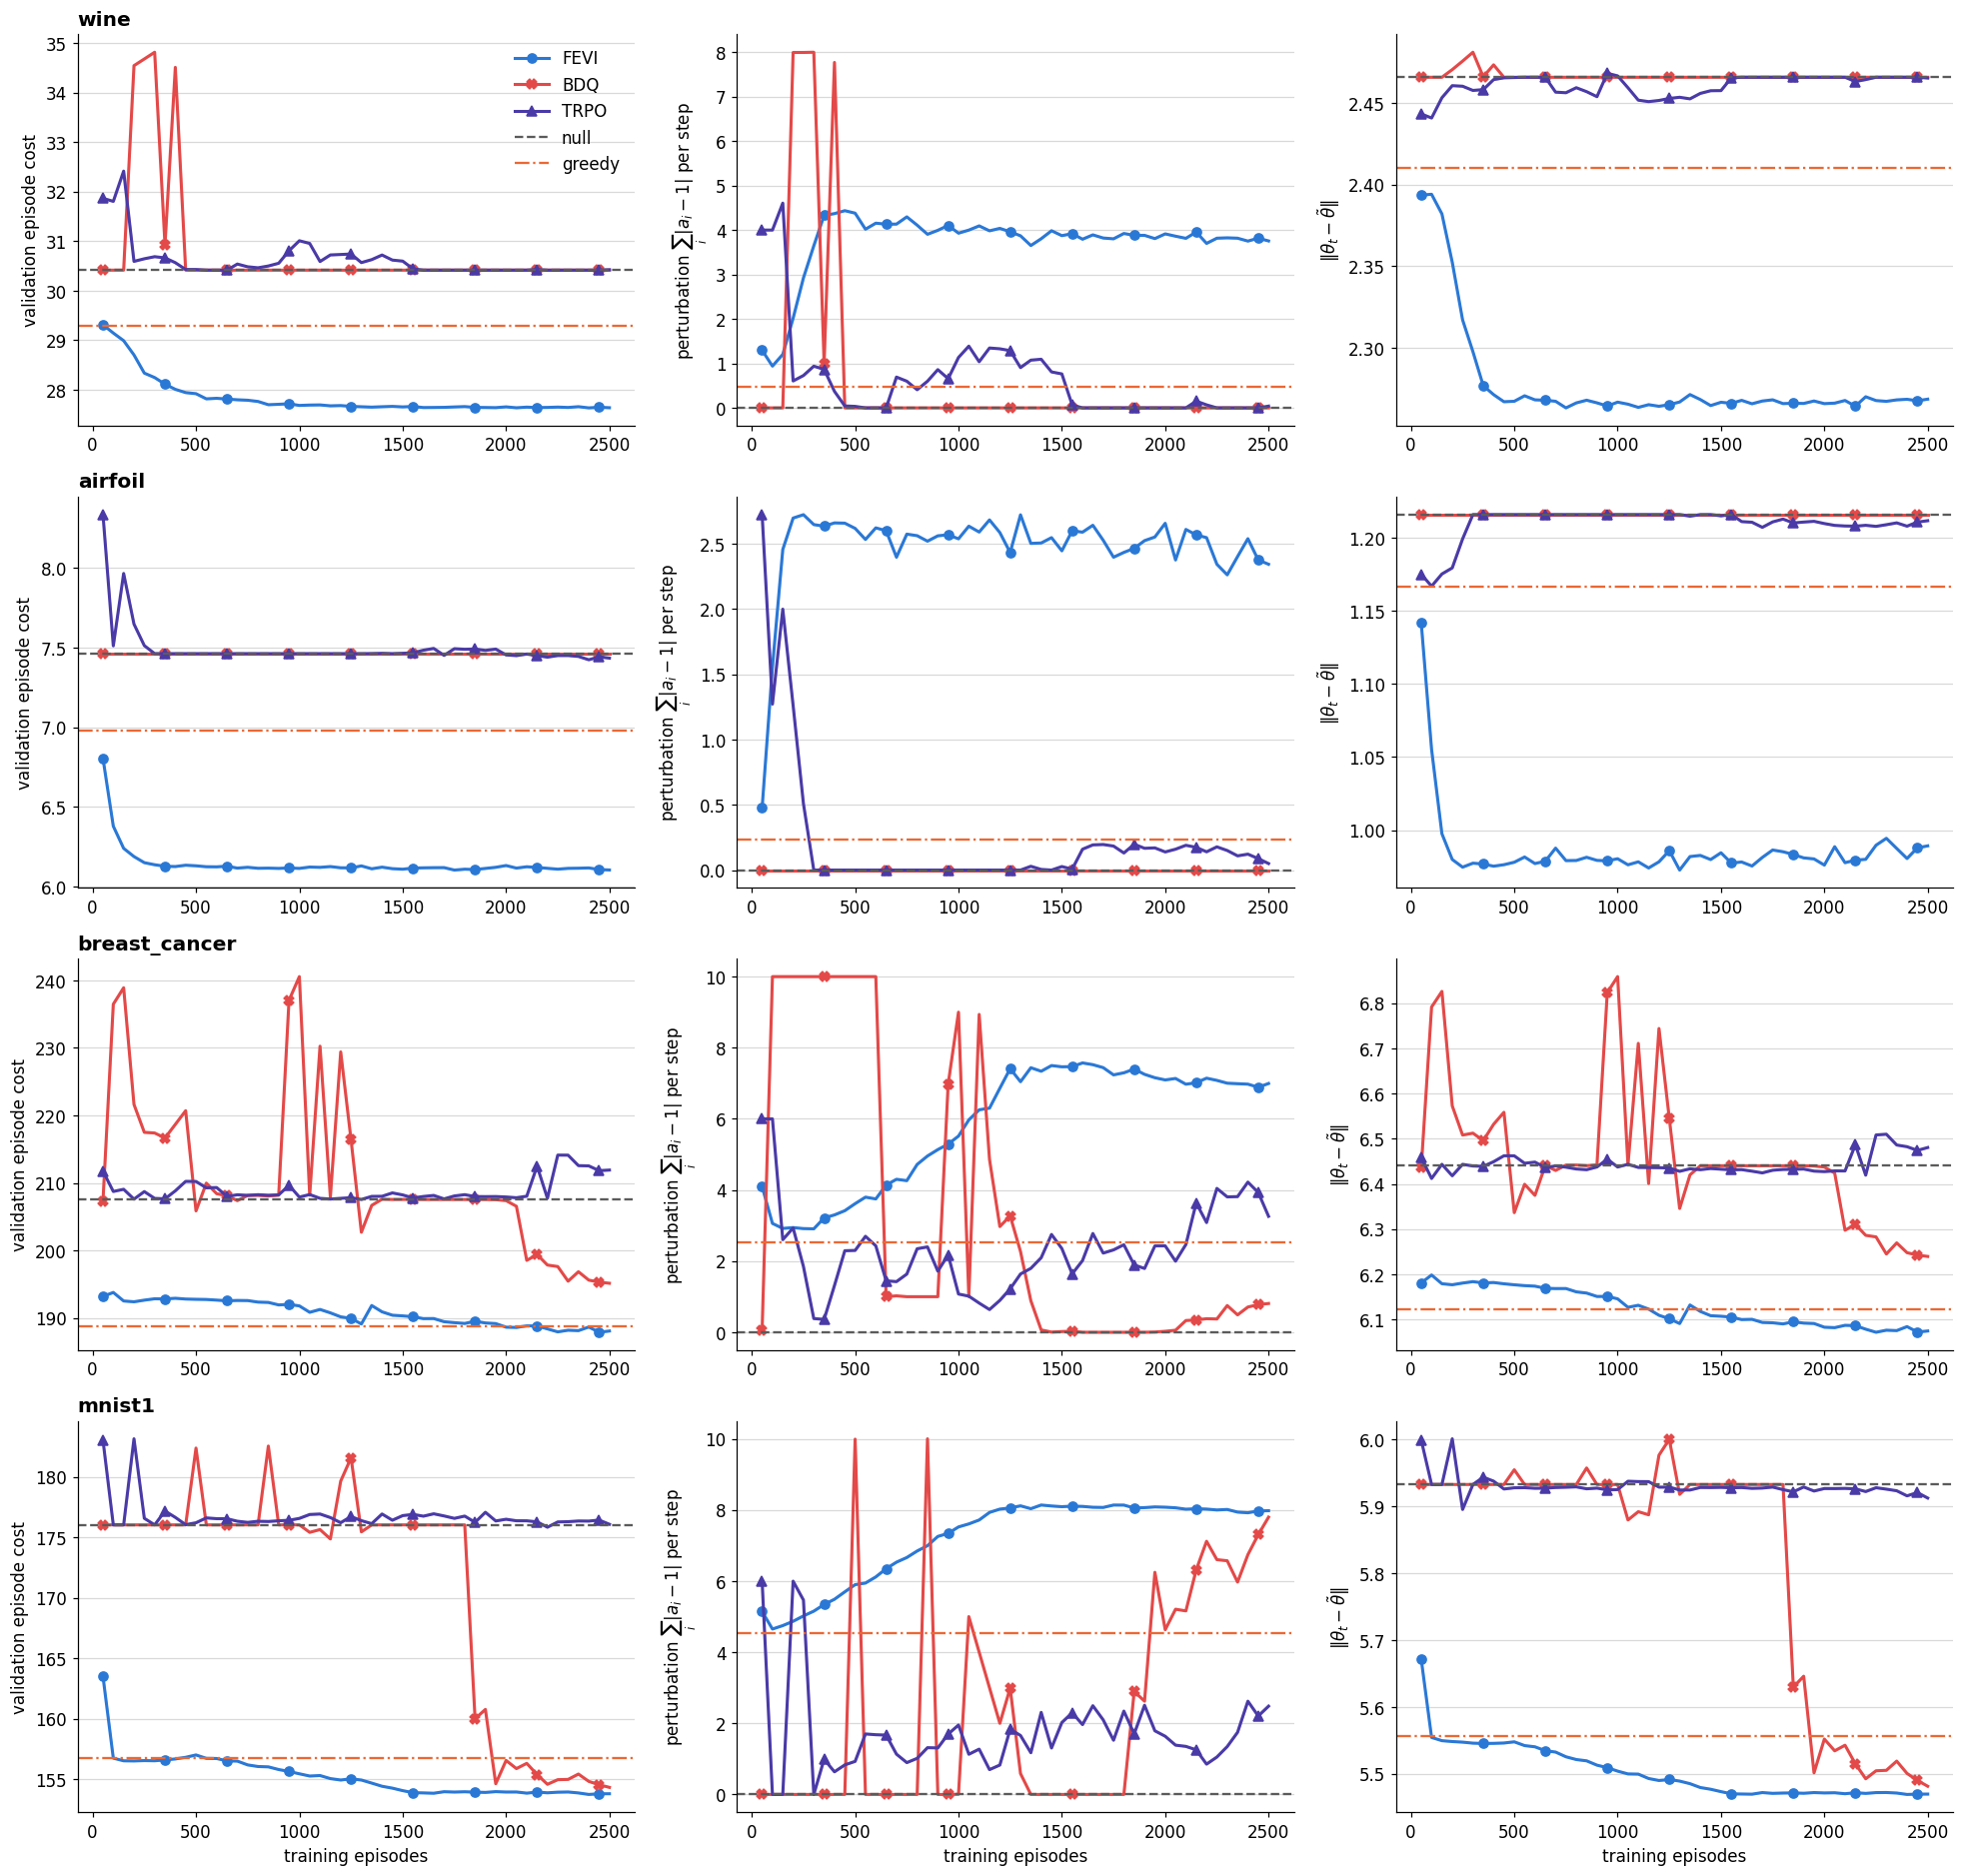


[wine] val. cost, last iter      mean      std
----------------------------------------------
FEVI                          27.638    0.000
BDQ                           30.415    0.000
TRPO                          30.424    0.000

[airfoil] val. cost, last iter      mean      std
-------------------------------------------------
FEVI                           6.103    0.000
BDQ                            7.462    0.000
TRPO                           7.434    0.000

[breast_cancer] val. cost, last iter      mean      std
-------------------------------------------------------
FEVI                         188.084    0.000
BDQ                          195.153    0.000
TRPO                         211.912    0.000

[mnist1] val. cost, last iter      mean      std
------------------------------------------------
FEVI                         153.783    0.000
BDQ                          154.310    0.000
TRPO                         176.085    0.000


In [21]:
PANELS = [("cost", "validation episode cost"),
          ("pert", r"perturbation $\sum_i |a_i - 1|$ per step"),
          ("gap", r"$\|\theta_t - \tilde{\theta}\|$")]


def curve_stats(t, name, key):
    H = np.array([lg[name][key] for lg in per_seed(t, "logs")])
    return H.mean(0), H.std(0)


fig, axes = plt.subplots(len(SHOWN), 3, figsize=(18, 4.3 * len(SHOWN)), squeeze=False)
for row, t in enumerate(SHOWN):
    ref = {n: np.mean([r[n] for r in per_seed(t, "ref")], axis=0) for n in ["null", "greedy"]}
    for col, (key, ylabel) in enumerate(PANELS):
        ax = axes[row, col]
        for n in LEARNERS:
            mu, sd = curve_stats(t, n, key)
            x = np.arange(1, len(mu) + 1) * res[t]["episodes_per_update"]
            ax.plot(x, mu, f"{MARKERS[n]}-", color=COLORS[n], lw=2, label=n,
                    markevery=max(1, len(x) // 8))
            ax.fill_between(x, mu - sd, mu + sd, color=COLORS[n], alpha=0.15)
        ax.axhline(ref["null"][col], color=COLORS["null"], ls="--", lw=1.5, label="null")
        ax.axhline(ref["greedy"][col], color=COLORS["greedy"], ls="-.", lw=1.5,
                   label="greedy")
        ax.set_ylabel(ylabel)
        if row == len(SHOWN) - 1:
            ax.set_xlabel("training episodes")
    axes[row, 0].set_title(t, loc="left", fontweight="bold")
axes[0, 0].legend(loc="upper right")
plt.tight_layout()
plt.show()

for t in SHOWN:
    print_raw(f"[{t}] val. cost, last iter",
              {n: [h[n][-1] for h in per_seed(t, "hist")] for n in LEARNERS})

### Time

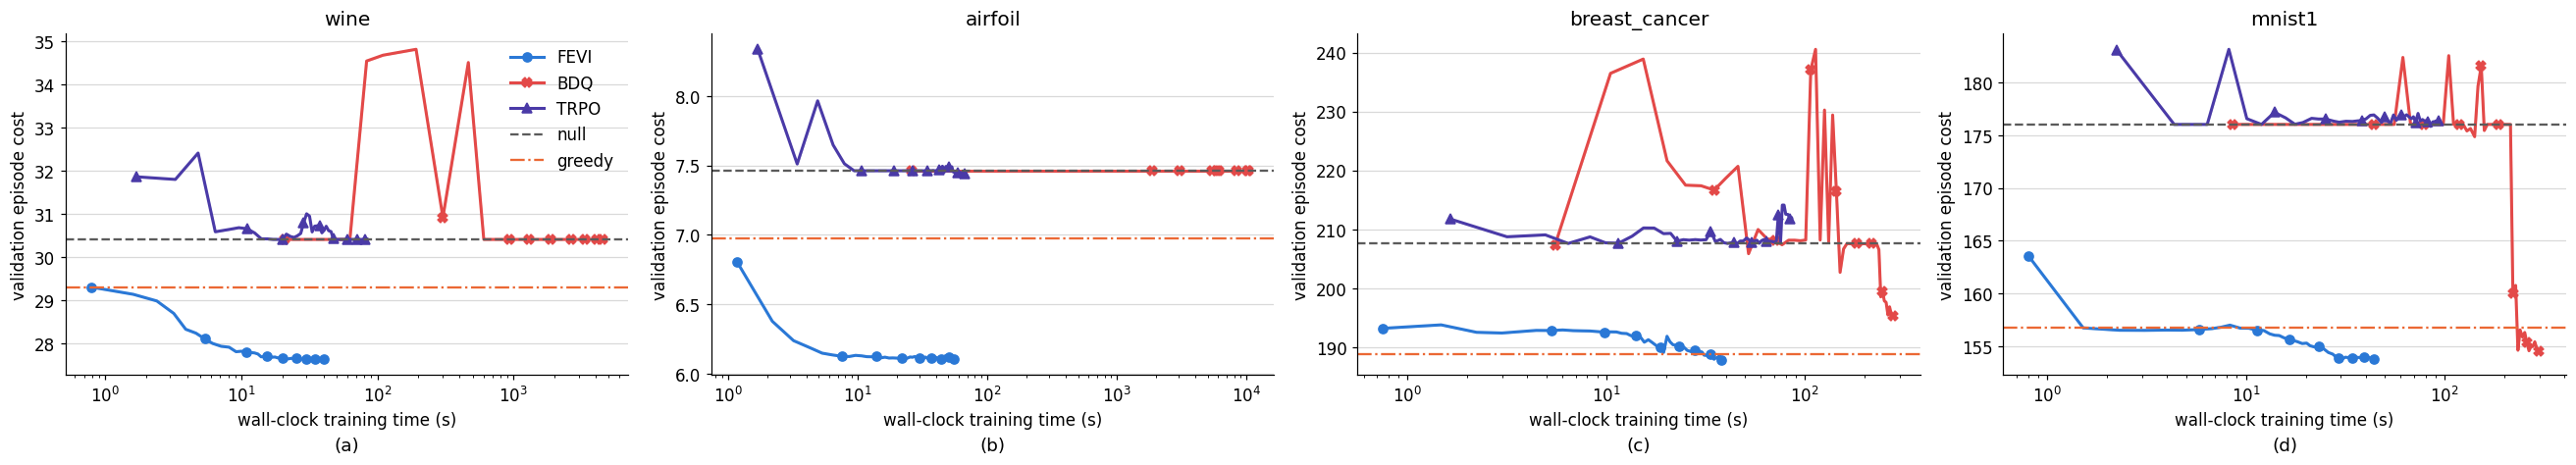


[wine] training time (s)        mean      std
---------------------------------------------
FEVI                           125.9      0.0
BDQ                           4627.1      0.0
TRPO                           141.7      0.0

[airfoil] training time (s)      mean      std
----------------------------------------------
FEVI                           172.4      0.0
BDQ                          10542.1      0.0
TRPO                           113.3      0.0

[breast_cancer] training time (s)      mean      std
----------------------------------------------------
FEVI                           121.6      0.0
BDQ                            385.1      0.0
TRPO                           140.4      0.0

[mnist1] training time (s)      mean      std
---------------------------------------------
FEVI                           144.8      0.0
BDQ                            404.5      0.0
TRPO                           157.1      0.0


In [22]:
fig, axes = plt.subplots(1, len(SHOWN), figsize=(6 * len(SHOWN), 4.5), squeeze=False)
for k, (ax, t) in enumerate(zip(axes[0], SHOWN)):
    ref = {n: np.mean([r[n] for r in per_seed(t, "ref")], axis=0) for n in ["null", "greedy"]}
    for n in LEARNERS:
        mu_t, _ = curve_stats(t, n, "time")
        mu, sd = curve_stats(t, n, "cost")
        ax.plot(mu_t, mu, f"{MARKERS[n]}-", color=COLORS[n], lw=2, label=n,
                markevery=max(1, len(mu) // 8))
        ax.fill_between(mu_t, mu - sd, mu + sd, color=COLORS[n], alpha=0.15)
    ax.axhline(ref["null"][0], color=COLORS["null"], ls="--", lw=1.5, label="null")
    ax.axhline(ref["greedy"][0], color=COLORS["greedy"], ls="-.", lw=1.5, label="greedy")
    ax.set_xscale("log")
    ax.set_xlabel("wall-clock training time (s)")
    ax.set_ylabel("validation episode cost")
    ax.set_title(t)
    ax.text(0.5, -0.18, f"({'abcdefgh'[k]})", transform=ax.transAxes, ha="center", va="top",
            fontsize=12)
axes[0, 0].legend()
plt.tight_layout()
plt.show()

for t in SHOWN:
    print_raw(f"[{t}] training time (s)", {n: [tm[n] for tm in per_seed(t, "times")]
                                            for n in LEARNERS}, 1)